# HCI Evaluation Analysis: Prototype Comparison (N = 14)
This notebook processes raw Likert survey responses and forced preference rankings across three low-fidelity prototypes:
- **Prototype 1:** Persistent Context Booking Flow
- **Prototype 2:** Complexity-Scaled Trip Planner
- **Prototype 3:** Resilient Planning Companion

In [4]:
import pandas as pd
import numpy as np
from scipy import stats

# Load raw survey data (14 responses)
data = [
    [1, "Somewhat easy", "Somewhat confident", "Somewhat clear", "Somewhat easy", "Somewhat confident", "Somewhat clear", "Neutral", "Neutral", "Neutral", "2, 1, 3"],
    [2, "Somewhat easy", "Somewhat unconfident", "Somewhat clear", "Extremely difficult", "Extremely unconfident", "Somewhat unclear", "Extremely difficult", "Extremely unconfident", "Somewhat clear", "1, 2, 3"],
    [3, "Somewhat easy", "Somewhat unconfident", "Somewhat clear", "Somewhat difficult", "Somewhat unconfident", "Somewhat unclear", "Neutral", "Somewhat confident", "Extremely clear", "1, 2, 3"],
    [4, "Somewhat easy", "Extremely confident", "Somewhat clear", "Somewhat difficult", "Extremely unconfident", "Extremely unclear", "Extremely easy", "Somewhat confident", "Extremely clear", "1, 3, 2"],
    [5, "Somewhat easy", "Somewhat confident", "Somewhat clear", "Somewhat easy", "Somewhat confident", "Neutral", "Extremely easy", "Extremely confident", "Extremely clear", "3, 2, 1"],
    [6, "Somewhat easy", "Somewhat confident", "Extremely clear", "Somewhat easy", "Somewhat confident", "Somewhat clear", "Extremely easy", "Somewhat confident", "Extremely clear", "3, 1, 2"],
    [7, "Somewhat easy", "Somewhat confident", "Somewhat clear", "Somewhat easy", "Somewhat confident", "Somewhat clear", "Extremely easy", "Extremely confident", "Extremely clear", "3, 1, 2"],
    [8, "Extremely easy", "Somewhat confident", "Somewhat clear", "Somewhat difficult", "Somewhat unconfident", "Somewhat unclear", "Somewhat difficult", "Extremely unconfident", "Extremely unclear", "1, 3, 2"],
    [9, "Neutral", "Somewhat unconfident", "Somewhat clear", "Somewhat difficult", "Somewhat confident", "Neutral", "Somewhat difficult", "Extremely confident", "Somewhat clear", "3, 2, 1"],
    [10, "Neutral", "Somewhat confident", "Somewhat clear", "Neutral", "Neutral", "Somewhat unclear", "Neutral", "Somewhat confident", "Neutral", "2, 3, 1"],
    [11, "Neutral", "Somewhat unconfident", "Somewhat unclear", "Somewhat difficult", "Somewhat unconfident", "Extremely unclear", "Somewhat easy", "Neutral", "Extremely clear", "3, 1, 2"],
    [12, "Extremely easy", "Extremely confident", "Extremely clear", "Somewhat difficult", "Somewhat unconfident", "Somewhat clear", "Extremely difficult", "Extremely unconfident", "Somewhat unclear", "1, 2, 3"],
    [13, "Somewhat easy", "Neutral", "Somewhat clear", "Somewhat easy", "Neutral", "Somewhat clear", "Neutral", "Somewhat unconfident", "Neutral", "1, 2, 3"],
    [14, "Extremely easy", "Somewhat confident", "Somewhat clear", "Somewhat easy", "Neutral", "Somewhat clear", "Somewhat easy", "Somewhat confident", "Extremely clear", "1, 3, 2"]
]

columns = ["id", "P1_Q1", "P1_Q2", "P1_Q3", "P2_Q6", "P2_Q7", "P2_Q8", "P3_Q11", "P3_Q12", "P3_Q13", "Q16_rank"]
df = pd.DataFrame(data, columns=columns)
df.head()

,id,P1_Q1,P1_Q2,P1_Q3,P2_Q6,P2_Q7,P2_Q8,P3_Q11,P3_Q12,P3_Q13,Q16_rank
0,1,Somewhat easy,Somewhat confident,Somewhat clear,Somewhat easy,Somewhat confident,Somewhat clear,Neutral,Neutral,Neutral,"2, 1, 3"
1,2,Somewhat easy,Somewhat unconfident,Somewhat clear,Extremely difficult,Extremely unconfident,Somewhat unclear,Extremely difficult,Extremely unconfident,Somewhat clear,"1, 2, 3"
2,3,Somewhat easy,Somewhat unconfident,Somewhat clear,Somewhat difficult,Somewhat unconfident,Somewhat unclear,Neutral,Somewhat confident,Extremely clear,"1, 2, 3"
3,4,Somewhat easy,Extremely confident,Somewhat clear,Somewhat difficult,Extremely unconfident,Extremely unclear,Extremely easy,Somewhat confident,Extremely clear,"1, 3, 2"
4,5,Somewhat easy,Somewhat confident,Somewhat clear,Somewhat easy,Somewhat confident,Neutral,Extremely easy,Extremely confident,Extremely clear,"3, 2, 1"


In [5]:
# Map qualitative responses to 1-5 numerical scale
likert_ease = {"Extremely difficult": 1, "Somewhat difficult": 2, "Neutral": 3, "Somewhat easy": 4, "Extremely easy": 5}
likert_conf = {"Extremely unconfident": 1, "Somewhat unconfident": 2, "Neutral": 3, "Somewhat confident": 4, "Extremely confident": 5}
likert_clear = {"Extremely unclear": 1, "Somewhat unclear": 2, "Neutral": 3, "Somewhat clear": 4, "Extremely clear": 5}

# Convert columns
df['P1_Q1_num'] = df['P1_Q1'].map(likert_ease)
df['P1_Q2_num'] = df['P1_Q2'].map(likert_conf)
df['P1_Q3_num'] = df['P1_Q3'].map(likert_clear)

df['P2_Q6_num'] = df['P2_Q6'].map(likert_ease)
df['P2_Q7_num'] = df['P2_Q7'].map(likert_conf)
df['P2_Q8_num'] = df['P2_Q8'].map(likert_clear)

df['P3_Q11_num'] = df['P3_Q11'].map(likert_ease)
df['P3_Q12_num'] = df['P3_Q12'].map(likert_conf)
df['P3_Q13_num'] = df['P3_Q13'].map(likert_clear)

# Summary table for Descriptive Statistics
stats_summary = pd.DataFrame({
    'Metric': ['Q1/Q6/Q11 (Ease)', 'Q2/Q7/Q12 (Confidence)', 'Q3/Q8/Q13 (Clarity)'],
    'P1 Mean (SD)': [f"{df['P1_Q1_num'].mean():.2f} ({df['P1_Q1_num'].std():.2f})", f"{df['P1_Q2_num'].mean():.2f} ({df['P1_Q2_num'].std():.2f})", f"{df['P1_Q3_num'].mean():.2f} ({df['P1_Q3_num'].std():.2f})"],
    'P2 Mean (SD)': [f"{df['P2_Q6_num'].mean():.2f} ({df['P2_Q6_num'].std():.2f})", f"{df['P2_Q7_num'].mean():.2f} ({df['P2_Q7_num'].std():.2f})", f"{df['P2_Q8_num'].mean():.2f} ({df['P2_Q8_num'].std():.2f})"],
    'P3 Mean (SD)': [f"{df['P3_Q11_num'].mean():.2f} ({df['P3_Q11_num'].std():.2f})", f"{df['P3_Q12_num'].mean():.2f} ({df['P3_Q12_num'].std():.2f})", f"{df['P3_Q13_num'].mean():.2f} ({df['P3_Q13_num'].std():.2f})"]
})

stats_summary

,Metric,P1 Mean (SD),P2 Mean (SD),P3 Mean (SD)
0,Q1/Q6/Q11 (Ease),4.00 (0.68),2.86 (1.10),3.29 (1.44)
1,Q2/Q7/Q12 (Confidence),3.50 (1.09),2.79 (1.12),3.29 (1.49)
2,Q3/Q8/Q13 (Clarity),4.00 (0.68),2.86 (1.17),3.93 (1.33)


In [6]:
# 1. ANOVA - Core Clarity
f_clarity, p_clarity = stats.f_oneway(df['P1_Q3_num'], df['P2_Q8_num'], df['P3_Q13_num'])
print(f"One-Way ANOVA (Clarity): F = {f_clarity:.3f}, p = {p_clarity:.4f}")

# Pairwise t-test P1 vs P2 (Clarity)
ttest_p1_p2 = stats.ttest_rel(df['P1_Q3_num'], df['P2_Q8_num'])
print(f"Post-hoc t-test P1 vs P2 (Clarity): t = {ttest_p1_p2.statistic:.3f}, p = {ttest_p1_p2.pvalue:.4f}")

# 2. ANOVA - Ease of Navigation
f_ease, p_ease = stats.f_oneway(df['P1_Q1_num'], df['P2_Q6_num'], df['P3_Q11_num'])
print(f"One-Way ANOVA (Ease): F = {f_ease:.3f}, p = {p_ease:.4f}")

# 3. Preference Rankings & Chi-Square Test
df['top_choice'] = df['Q16_rank'].apply(lambda r: f"Prototype {[c for c in r if c in '123'][0]}")
counts = df['top_choice'].value_counts()
chi2, p_chi2 = stats.chisquare([counts.get('Prototype 1', 0), counts.get('Prototype 2', 0), counts.get('Prototype 3', 0)])
print(f"Chi-Square Test (Top Preference): Chi2 = {chi2:.3f}, p = {p_chi2:.4f}")

One-Way ANOVA (Clarity): F = 4.798, p = 0.0137
Post-hoc t-test P1 vs P2 (Clarity): t = 4.505, p = 0.0006
One-Way ANOVA (Ease): F = 3.747, p = 0.0325
Chi-Square Test (Top Preference): Chi2 = 2.714, p = 0.2574


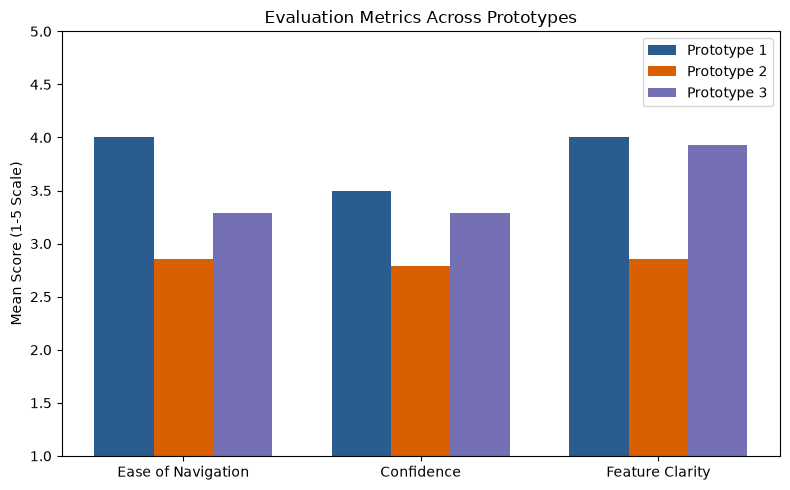

In [8]:
import matplotlib.pyplot as plt

# Bar chart of Mean Usability Scores
means_p1 = [df['P1_Q1_num'].mean(), df['P1_Q2_num'].mean(), df['P1_Q3_num'].mean()]
means_p2 = [df['P2_Q6_num'].mean(), df['P2_Q7_num'].mean(), df['P2_Q8_num'].mean()]
means_p3 = [df['P3_Q11_num'].mean(), df['P3_Q12_num'].mean(), df['P3_Q13_num'].mean()]

x = np.arange(3)
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar(x - width, means_p1, width, label='Prototype 1', color='#2b5c8f')
plt.bar(x, means_p2, width, label='Prototype 2', color='#d95f02')
plt.bar(x + width, means_p3, width, label='Prototype 3', color='#7570b3')

plt.ylabel('Mean Score (1-5 Scale)')
plt.title('Evaluation Metrics Across Prototypes')
plt.xticks(x, ['Ease of Navigation', 'Confidence', 'Feature Clarity'])
plt.ylim(1, 5)
plt.legend()
plt.tight_layout()
plt.show()